In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Load Dataset
df = pd.read_csv('../dataset/heart_disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
0,63,1,3,145,233,1,0,150,0,2.3,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,1
2,41,0,1,130,204,0,0,172,0,1.4,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,1


### Step 2: Exploratory Data Analysis (EDA)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       193 non-null    int64  
 1   sex       193 non-null    int64  
 2   cp        193 non-null    int64  
 3   trestbps  193 non-null    int64  
 4   chol      193 non-null    int64  
 5   fbs       193 non-null    int64  
 6   restecg   193 non-null    int64  
 7   thalach   193 non-null    int64  
 8   exang     193 non-null    int64  
 9   oldpeak   193 non-null    float64
 10  slope     193 non-null    int64  
 11  target    193 non-null    int64  
dtypes: float64(1), int64(11)
memory usage: 18.2 KB
None

Class Balance:
target
1    0.544041
0    0.455959
Name: proportion, dtype: float64


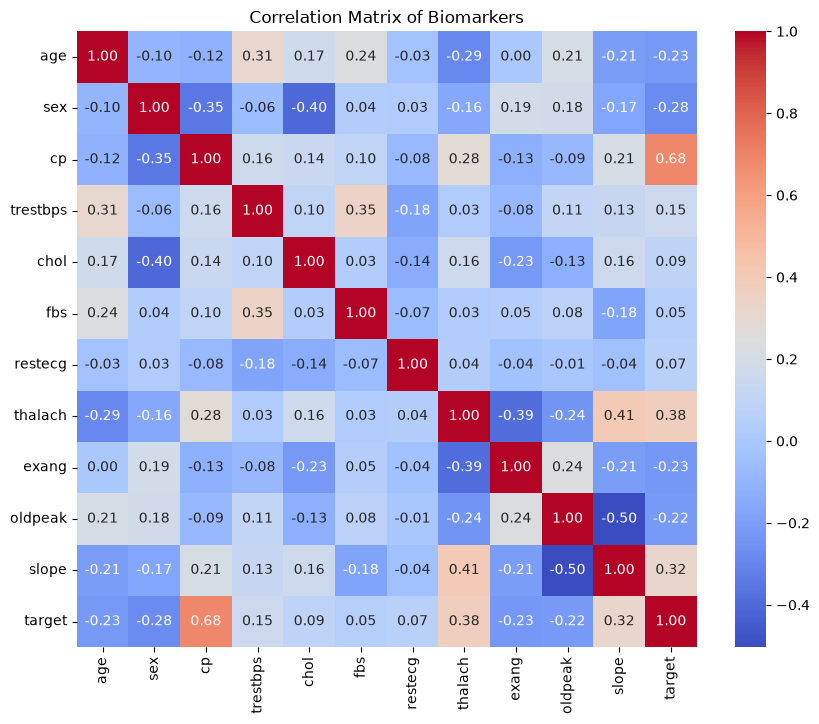

In [5]:
# Dataset Information & Missing Values
print('Dataset Info:')
print(df.info())

# Class Balance
print('\nClass Balance:')
print(df['target'].value_counts(normalize=True))

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix of Biomarkers')
plt.show()

### Step 3: Data Preprocessing

In [6]:
X = df.drop(columns=['target'])
y = df['target']

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Train shape: {X_train_scaled.shape}, Test shape: {X_test_scaled.shape}')

Train shape: (154, 11), Test shape: (39, 11)


### Step 4: Model Training & Comparative Evaluation

In [8]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    'K-NN': KNeighborsClassifier(n_neighbors=5),
    'MLP Neural Net': MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    
    auc = roc_auc_score(y_test, proba)
    report = classification_report(y_test, preds, output_dict=True)
    
    results[name] = {
        'Accuracy': report['accuracy'],
        'Precision': report['1']['precision'],
        'Recall': report['1']['recall'],
        'F1-Score': report['1']['f1-score'],
        'ROC-AUC': auc
    }

pd.DataFrame(results).T

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.846154,0.941176,0.761905,0.842105,0.931217
Decision Tree,0.794872,0.782609,0.857143,0.818182,0.899471
Random Forest,0.974359,1.000000,0.952381,0.975610,1.000000
K-NN,0.846154,0.826087,0.904762,0.863636,0.923280
MLP Neural Net,0.923077,0.950000,0.904762,0.926829,0.989418


### Step 5: Feature Importance & Explainable AI (XAI)

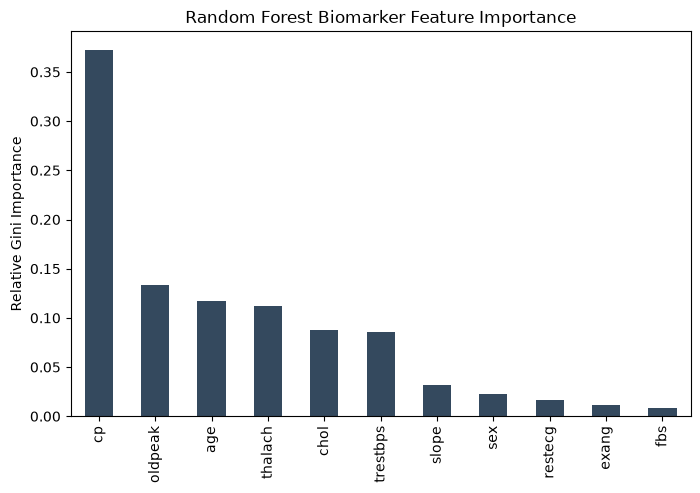

In [9]:
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances.plot(kind='bar', color='#34495e')
plt.title('Random Forest Biomarker Feature Importance')
plt.ylabel('Relative Gini Importance')
plt.show()